# TN3K · EDA sonrası veri hazırlama analizi

Bu notebook, gerçek ultrason–maske çiftlerinin dosyadan girdi tensörüne nasıl dönüştüğünü inceler. Mevcut veri ayrımını ve dosya içeriklerini doğrular, ardından padding geri alındığında özgün alandaki piksellerin korunup korunmadığını ölçer. Colab’da CPU yeterlidir.

**Gerçek akış**  
Mevcut ayrım ve dosya eşleştirme → gri ton ve ikili maske → yalnız eğitimde olası ortak yatay çevirme → görüntüyü 0–1 aralığına ölçekleme → sağ/alt sıfır dolgusu ve geçerli alan maskesi → tensörler.

**Kaynak notebook’lar**

- `TN3K_EDA_ve_UNet_Tam_Notebook_Unet3.ipynb` · 8, 12, 18–22 ve 24. bölümler. Eşik taraması, resize demosu, özgün çözünürlükte işleme ve geçerli alan maskesi.
- `TN3K_Base_UNet_Epoch27_Test_Colab.ipynb` · 4–6. bölümler. Doğrulanmış manifest, ortak ön işleme ve test örneğinin özgün boyuta dönüşü.
- `TN3K_UNet3Plus_Colab_Egitim.ipynb` · 2–4. bölümler. Aynı ayrımın kullanımı, ortak ön işleme ve eğitim veri yükleyicisi.

Üç kaynakta `read_image_mask`, `preprocess_native_pair` ve veri yükleyicisinin ilgili tanımları aynı. Bu incelemede model çalıştırmadan veri hazırlama kodunu kullanıyorum. Kaynak EDA’ya ait sayıları geçmiş bulgu olarak, bu çalıştırmada ölçülenleri çıktı tablolarında gösteriyorum.

## 1 · Drive ve veri yolları

Drive’ı bağlayıp doğrulanmış manifesti açıyorum. Varsayılan TN3K v2 kaynağını değiştirmek için yalnızca veri kökünü düzenle.

In [1]:
EXPECTED_MANIFEST_SHA256 = '8e7f07f36625f59bd0f233e8c4f84ecc4e0f181fbad77788c6513f1d4df6867b'

from pathlib import Path

DATASET_ROOT = ""  # Boşsa TN3K v2 hazırlanır.
MANIFEST_PATH = Path(
    "/content/drive/MyDrive/TN3K/BaseUNet/Test_Sonuclari/"
    "Base_UNet_Epoch27_20261124T160223Z_a8532dfd/verified_split_manifest.csv"
)

from google.colab import drive
drive.mount("/content/drive")

import hashlib
import math
import random
from collections import Counter
from dataclasses import dataclass
from unittest.mock import patch
from typing import Any
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from PIL import Image as PILImage
from tqdm.auto import tqdm
import torch
from torch.utils.data import Dataset, DataLoader

if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(f"Doğrulanmış manifest bulunamadı: {MANIFEST_PATH}")

manifest_digest = hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest()
if manifest_digest != EXPECTED_MANIFEST_SHA256:
    raise ValueError(f"Bu manifest iki modelde kullanılan doğrulanmış dosyayla eşleşmiyor: {manifest_digest}")

if DATASET_ROOT.strip():
    root = Path(DATASET_ROOT).expanduser().resolve()
else:
    try:
        import kagglehub
    except ModuleNotFoundError:
        import subprocess
        import sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
        import kagglehub
    root = Path(kagglehub.dataset_download(
        "tjahan/tn3k-thyroid-nodule-region-segmentation-dataset/versions/2"
    )).resolve()
print("Veri kökü:", root)
print("Doğrulanmış manifest:", MANIFEST_PATH)

Mounted at /content/drive


100%|██████████| 176M/176M [00:01<00:00, 134MB/s] 

Extracting files...


Veri kökü: /root/.cache/kagglehub/datasets/tjahan/tn3k-thyroid-nodule-region-segmentation-dataset/versions/2
Doğrulanmış manifest: /content/drive/MyDrive/TN3K/BaseUNet/Test_Sonuclari/Base_UNet_Epoch27_20261124T160223Z_a8532dfd/verified_split_manifest.csv


## 2 · Mevcut ayrım ve çiftlerin bütünlüğü

Dosyaları kaynak bölüm ve örnek adıyla yeniden bağlıyorum. Tablo, mevcut çalıştırmada okunabilen çiftleri, eksikleri, boyut ve içerik uyuşmazlıklarını özetler.

In [2]:
expected = {"train": 2303, "val": 576, "test": 614}
pairs = pd.read_csv(MANIFEST_PATH, dtype={"filename": str})
counts = pairs["subset"].value_counts().to_dict()
sources = pairs["subset"].map({"train": "trainval", "val": "trainval", "test": "test"})
if counts != expected or pairs.duplicated(["split", "filename"]).any() or not pairs["split"].eq(sources).all():
    raise ValueError(f"Manifest üyelikleri veya örnek kimlikleri geçersiz: {counts}")

file_issues = []
present = {}
for split, rows in pairs.groupby("split"):
    names = set(rows["filename"])
    for kind in ("image", "mask"):
        folder = root / f"{split}-{kind}"
        if not folder.is_dir():
            raise FileNotFoundError(f"Beklenen veri klasörü yok: {folder}")
        present[split, kind] = {p.name for p in folder.glob("*.jpg")}
        for name in sorted(present[split, kind] - names):
            file_issues.append((f"{split}/{name}", f"Manifest dışında {kind} dosyası"))
        pairs.loc[rows.index, f"{kind}_path"] = [str(folder / name) for name in rows["filename"]]

def pixel_hash(array):
    return hashlib.sha256(str(array.shape).encode() + array.tobytes()).hexdigest()

def gray(path):
    with Image.open(path) as source:
        return np.array(source.convert("L"))

audit = {subset: Counter() for subset in expected}
for row in tqdm(pairs.itertuples(index=False), total=len(pairs), desc="Görüntü ve maskeler"):
    stats = audit[row.subset]
    sample_id = f"{row.split}/{row.filename}"
    missing = [kind for kind in ("image", "mask") if row.filename not in present[row.split, kind]]
    if missing:
        stats["Eksik çift"] += 1
        file_issues.append((sample_id, f"Eksik dosya: {', '.join(missing)}"))
        continue
    try:
        image, raw_mask = gray(row.image_path), gray(row.mask_path)
    except OSError as error:
        stats["Okunamayan çift"] += 1
        file_issues.append((sample_id, str(error)))
        continue
    stats["Okunabilen çift"] += 1
    if image.shape != raw_mask.shape or image.shape != (row.height, row.width):
        stats["Boyut uyuşmazlığı"] += 1
        file_issues.append((sample_id, f"Görüntü {image.shape}, maske {raw_mask.shape}, manifest {(row.height, row.width)}"))
        continue
    binary = (raw_mask >= 128).astype(np.uint8)
    if pixel_hash(image) != row.image_hash or pixel_hash(binary) != row.mask_hash:
        stats["İçerik uyuşmazlığı"] += 1
        file_issues.append((sample_id, "Gri görüntü veya ikili maske hash’i farklı"))

audit_columns = ["Okunabilen çift", "Eksik çift", "Okunamayan çift", "Boyut uyuşmazlığı", "İçerik uyuşmazlığı"]
audit_table = pd.DataFrame([
    {"Alt küme": subset, "Manifestte": counts[subset], **{key: audit[subset][key] for key in audit_columns}}
    for subset in expected
])
display(audit_table)
cross_split = pairs.groupby("image_hash")["subset"].transform("nunique").gt(1)
if cross_split.any():
    repeated = pairs.loc[cross_split, ["split", "filename", "subset"]]
    display(repeated.head())
    file_issues.append((repeated.iloc[0]["filename"], "Birebir görüntü farklı alt kümelerde"))
print("Alt kümeler arasında ortak görüntü hash’i:", pairs.loc[cross_split, "image_hash"].nunique())
if file_issues:
    display(pd.DataFrame(file_issues[:10], columns=["Örnek kimliği", "Sorun"]))
    raise ValueError(f"{len(file_issues)} veri sorunu bulundu. İlk sorun: {file_issues[0]}")

Görüntü ve maskeler:   0%|          | 0/3493 [00:00<?, ?it/s]

,Alt küme,Manifestte,Okunabilen çift,Eksik çift,Okunamayan çift,Boyut uyuşmazlığı,İçerik uyuşmazlığı
0,train,2303,2303,0,0,0,0
1,val,576,576,0,0,0,0
2,test,614,614,0,0,0,0


Alt kümeler arasında ortak görüntü hash’i: 0


Kaynak EDA’da **3.493 okunabilir çift** raporlanmıştı. Yukarıdaki tablo bugünkü dosyaları yeniden açarak hesaplanır. Hash, gri görüntüyü ve 128’de ikilileştirilmiş maskeyi doğrular. Pikseli birebir aynı görüntüler alt kümeler arasında aranır. Yakın kopyalar ve aynı hastaya ait farklı çekimler için hasta bilgisi gerekir.

## 3 · Tek kanallı görüntü ve ikili maske

Bir eğitim çiftini dosyadan açıp gri değerlerin 128 eşiğiyle nasıl etikete dönüştüğünü gösteriyorum. Tablo ve görsel eşik kararını denetler.

,Gözlenen gri değer,İkili etiket
0,0,0
1,1,0
2,2,0
3,253,1
4,254,1
5,255,1


,Eşik,Nodül pikseli,128 eşiğine göre farklı konum
0,64,13295,0
1,128,13295,0
2,192,13295,0


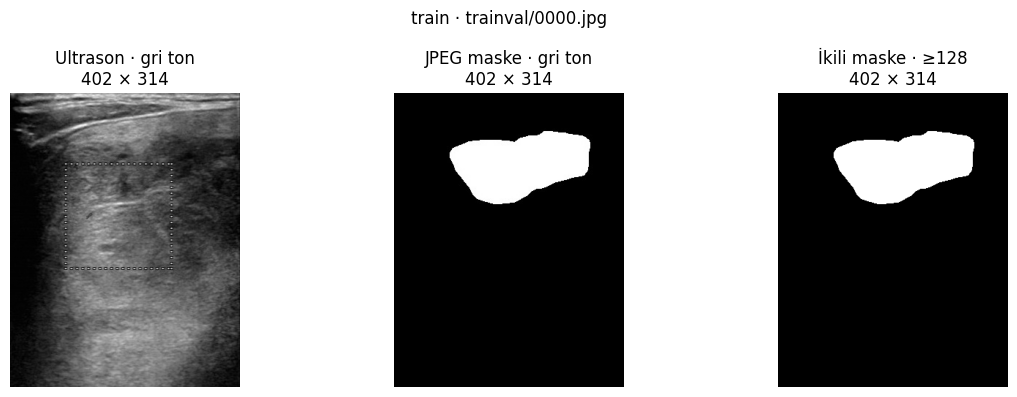

In [3]:
@dataclass(frozen=True)
class Config:
    seed: int = 42
    mask_threshold: int = 128
    intensity_scale: float = 255.0
    normalization: str = "scale"
    epsilon: float = 1e-6
    pad_multiple: int = 32
    fixed_input_hw: tuple | None = None
    padding_value: float = 0.0
    foreground_value: float = 1.0
    horizontal_flip_probability: float = 0.5
    batch_size: int = 1
    num_workers: int = 0
    pin_memory: bool = False
    device: str = "cpu"

cfg = Config()
def read_image_mask(image_path: str | Path, mask_path: str | Path, config: Config) -> tuple[np.ndarray, np.ndarray]:
    """EDA gibi PIL convert('L') kullan; önce maskeyi ikilileştir, resize yapma."""
    with Image.open(image_path) as image, Image.open(mask_path) as mask:
        if image.size != mask.size:
            raise ValueError(f'Görüntü/maske boyutu farklı: {image_path}')
        x = np.asarray(image.convert('L')).copy()
        y = (np.asarray(mask.convert('L')) >= config.mask_threshold).astype(np.uint8)
    return x, y

@dataclass(frozen=True)
class SpatialInfo:
    """Tahmini özgün koordinata döndürmek için saklanan boyutlar."""
    height: int
    width: int
    padded_height: int
    padded_width: int


def normalize_intensity(image: np.ndarray, config: Config) -> np.ndarray:
    """GT kullanmadan, padding eklenmeden önce yoğunluk ölçekle."""
    result = image.astype(np.float32) / config.intensity_scale
    if config.normalization == 'zscore':
        result = (result - result.mean()) / max(float(result.std()), config.epsilon)
    return result


def pad_without_resampling(image: np.ndarray, mask: np.ndarray, config: Config
                          ) -> tuple[np.ndarray, np.ndarray, np.ndarray, SpatialInfo]:
    """Sağ/alt padding; tüm kaynak pikselleri ve nodül etiketlerini birebir koru."""
    if image.shape != mask.shape or image.ndim != 2:
        raise ValueError('Ön işleme 2D eş boyutlu görüntü/maske bekliyor.')
    if not np.isin(mask, [config.padding_value, config.foreground_value]).all():
        raise ValueError('Maske ikili değil.')
    height, width = image.shape
    multiple = config.pad_multiple
    target_h, target_w = config.fixed_input_hw or (
        math.ceil(height / multiple) * multiple, math.ceil(width / multiple) * multiple)
    if target_h < height or target_w < width:
        raise ValueError('Canvas görüntüden küçük. Resize/crop yasak: canvas büyüt veya dinamik kullan.')
    padding = ((0, target_h - height), (0, target_w - width))
    padded_image = np.pad(image, padding, constant_values=config.padding_value)
    padded_mask = np.pad(mask, padding, constant_values=config.padding_value)
    valid = np.pad(np.ones(mask.shape, np.float32), padding, constant_values=config.padding_value)
    if not np.array_equal(padded_image[:height, :width], image):
        raise AssertionError('Görüntü pikselleri değişti.')
    if not np.array_equal(padded_mask[:height, :width], mask) or padded_mask.sum() != mask.sum():
        raise AssertionError('Maske pikselleri kayboldu veya yer değiştirdi.')
    return padded_image, padded_mask, valid, SpatialInfo(height, width, target_h, target_w)


def preprocess_native_pair(image_path: str | Path, mask_path: str | Path, config: Config,
                           augment: bool = False) -> tuple[np.ndarray, np.ndarray, np.ndarray, SpatialInfo]:
    """EDA preprocess_pair örneğinden ayrı, eğitimde kullanılan kayıpsız geometri."""
    image, mask = read_image_mask(image_path, mask_path, config)
    if augment and random.random() < config.horizontal_flip_probability:
        image, mask = np.fliplr(image).copy(), np.fliplr(mask).copy()
    return pad_without_resampling(normalize_intensity(image, config), mask, config)

class ThyroidNoduleDataset(Dataset):
    """EDA yollarını kullanır; yalnız train için ortak yatay flip uygular."""
    def __init__(self, table: pd.DataFrame, config: Config, augment: bool = False) -> None:
        self.table = table.reset_index(drop=True).copy()
        self.config = config
        self.augment = augment

    def __len__(self) -> int:
        return len(self.table)

    def __getitem__(self, index: int) -> dict[str, Any]:
        row = self.table.iloc[index]
        image, mask, valid, info = preprocess_native_pair(row.image_path, row.mask_path, self.config, self.augment)
        tensors = {name: torch.from_numpy(np.ascontiguousarray(array[None], dtype=np.float32))
                   for name, array in [('image', image), ('mask', mask), ('valid', valid)]}
        return {**tensors, 'height': info.height, 'width': info.width, 'index': index}


def seed_worker(worker_id: int) -> None:
    """DataLoader alt süreçlerinin Python/NumPy RNG durumlarını sabitle."""
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(table: pd.DataFrame, config: Config, training: bool = False) -> DataLoader:
    """Bir batch bir görüntü; farklı boyutları stack etme ihtiyacı yok."""
    generator = torch.Generator().manual_seed(config.seed)
    return DataLoader(ThyroidNoduleDataset(table, config, augment=training), batch_size=config.batch_size,
                      shuffle=training, num_workers=config.num_workers, worker_init_fn=seed_worker,
                      generator=generator, pin_memory=config.pin_memory and select_device(config).type == 'cuda')

def select_device(config: Config) -> torch.device:
    """GPU yoksa CPU; istenen CUDA yoksa sessiz fallback yerine hata."""
    name = ('cuda' if torch.cuda.is_available() else 'cpu') if config.device == 'auto' else config.device
    if name.startswith('cuda') and not torch.cuda.is_available():
        raise RuntimeError('CUDA istendi fakat kullanılamıyor.')
    return torch.device(name)

def hw(shape):
    height, width = shape
    return f"{height} × {width}"

def show_panels(items, title):
    fig, axes = plt.subplots(1, len(items), figsize=(4 * len(items), 4), squeeze=False)
    for axis, (array, label, maximum) in zip(axes[0], items):
        axis.imshow(array, cmap="gray", vmin=0, vmax=maximum)
        axis.set_title(f"{label}\n{hw(array.shape)}")
        axis.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

example_table = pairs.loc[pairs["subset"].eq("train")].sort_values("filename").head(1)
example = example_table.iloc[0]
label = f"{example['subset']} · {example['split']}/{example['filename']}"
raw, binary = read_image_mask(example.image_path, example.mask_path, cfg)
raw_mask = gray(example.mask_path)
assert np.array_equal(binary, raw_mask >= cfg.mask_threshold)
present_values = np.unique(raw_mask)
values = sorted(set(present_values[:3]).union(present_values[-3:]))
display(pd.DataFrame({"Gözlenen gri değer": values,
                      "İkili etiket": [int(value >= 128) for value in values]}))
thresholds = {t: raw_mask >= t for t in (64, 128, 192)}
display(pd.DataFrame([
    {"Eşik": t, "Nodül pikseli": int(mask.sum()),
     "128 eşiğine göre farklı konum": int(np.count_nonzero(mask != binary))}
    for t, mask in thresholds.items()
]))
show_panels([(raw, "Ultrason · gri ton", 255), (raw_mask, "JPEG maske · gri ton", 255),
             (binary, "İkili maske · ≥128", 1)], label)

Ana TN3K notebook’unda ilk 30 örneğe bakıldı, ardından **2.879 trainval maskesinde** 64, 128 ve 192 eşiklerinin **işaretli piksel oranları** karşılaştırıldı. Kaynak kod konumları doğrudan saymadı. Oran farkı sıfırdı. Aynı maskede eşik kümeleri iç içe olduğundan sıfır alan farkı, bu eşikler arasında seçilen piksel olmadığını da destekler. Yukarıdaki **yeni kontrol**, bu tek örnekte konum farkını doğrudan sayıyor.

## 4 · Ortak yatay çevirme ve ölçekleme

Bir eğitim örneğinde çevirme dalını kontrollü olarak çalıştırıyorum. Ardından ölçeklemenin veri tipi ve yoğunluk aralığı üzerindeki etkisini ölçüyorum.

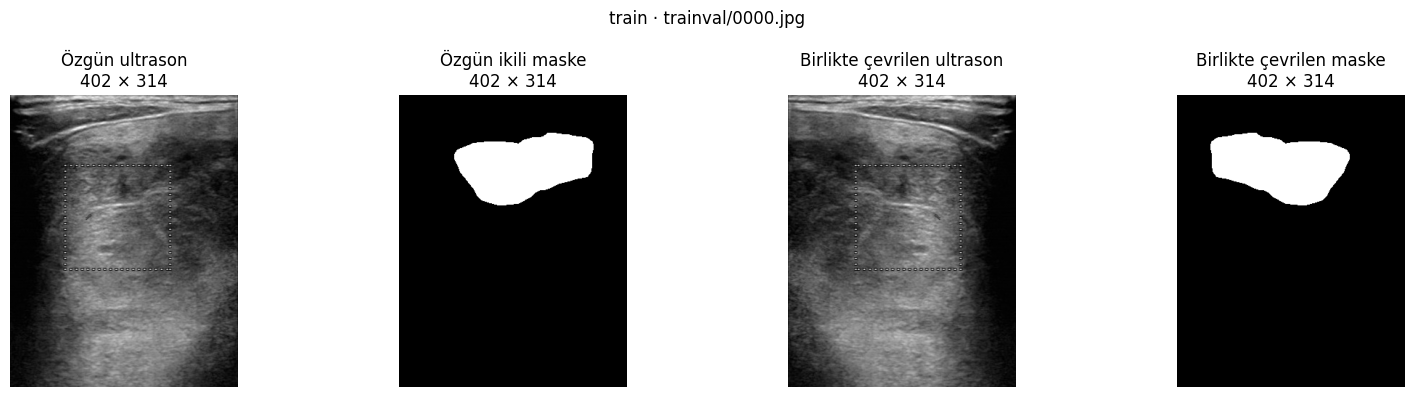

,Dizi,Tip,Teorik aralık,Min,Maks,Boyut
0,Görüntü,uint8,0–255,0.0,251.000000,402 × 314
1,Ölçekli görüntü,float32,0–1,0.0,0.984314,402 × 314
2,İkili maske,uint8,0–1,0.0,1.000000,402 × 314


Ortak çevirme, piksel hizası ve ölçekleme kontrolleri geçti.


In [4]:
# Bu denemede rastgele çekilişi 0,0 yaparak çevirme dalını seçiyoruz.
# Eğitimde kaynak kod her örnekte gerçek bir çekiliş yapar.
with patch.object(random, "random", return_value=0.0):
    flipped_pad, flipped_mask_pad, _, flip_info = preprocess_native_pair(
        example.image_path, example.mask_path, cfg, augment=True
    )
    eval_pad, eval_mask_pad, _, _ = preprocess_native_pair(
        example.image_path, example.mask_path, cfg, augment=False
    )

h, w = raw.shape
scaled = normalize_intensity(raw, cfg)
flipped = flipped_pad[:h, :w]
flipped_binary = flipped_mask_pad[:h, :w]
assert np.array_equal(flipped, normalize_intensity(np.fliplr(raw), cfg))
assert np.array_equal(flipped_binary, np.fliplr(binary))
assert np.array_equal(eval_pad[:h, :w], scaled)
assert np.array_equal(eval_mask_pad[:h, :w], binary)
assert raw.shape == scaled.shape and np.isin(binary, [0, 1]).all()

show_panels([(raw, "Özgün ultrason", 255), (binary, "Özgün ikili maske", 1),
             (flipped, "Birlikte çevrilen ultrason", 1), (flipped_binary, "Birlikte çevrilen maske", 1)], label)
display(pd.DataFrame([
    {"Dizi": name, "Tip": str(array.dtype), "Teorik aralık": span,
     "Min": float(array.min()), "Maks": float(array.max()), "Boyut": hw(array.shape)}
    for name, array, span in [("Görüntü", raw, "0–255"), ("Ölçekli görüntü", scaled, "0–1"),
                              ("İkili maske", binary, "0–1")]
]))
print("Ortak çevirme, piksel hizası ve ölçekleme kontrolleri geçti.")

Yatay çevirme eğitimde `random.random() < 0.5` koşuluyla uygulanır. Yukarıdaki gösterimde bu dalı bilerek seçtim. Doğrulama ve test yükleyicileri `training=False` ile `augment=False` geçirir. Ölçekleme, parlaklık değerlerini 255’e böler ve piksel koordinatlarını korur.

## 5 · Padding, geçerli alan ve girdi tensörleri

Sağ/alt sıfır dolgusu ile geçerli alanı gösteriyorum. Kaynak veri yükleyicisinin üç tensörünü ve gerçek test örneğinin boyutlarını doğruluyorum.

train · trainval/0000.jpg | 402 × 314 → 416 × 320
Alta eklenen: 14 px | Sağa eklenen: 6 px


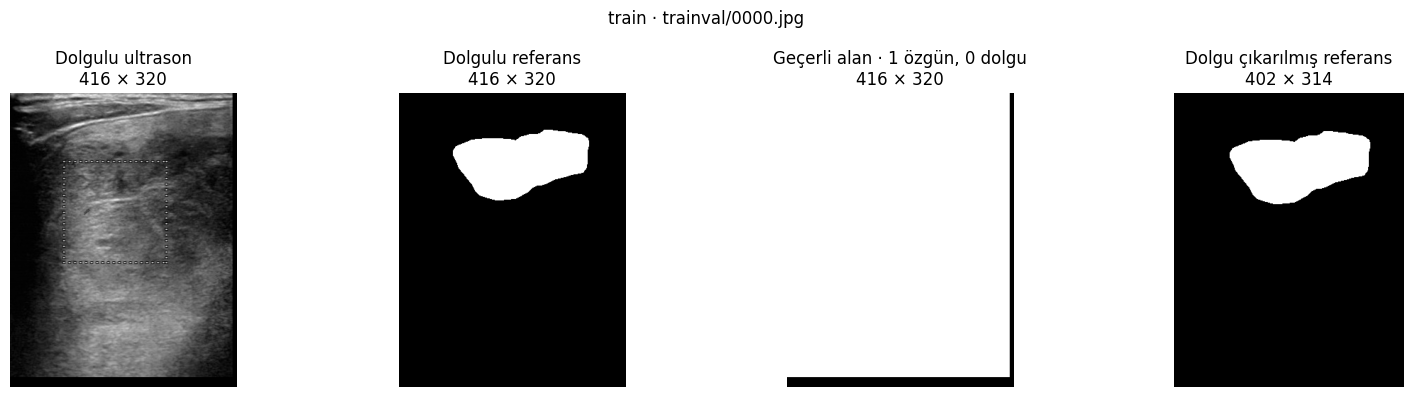

,Tensör,"Biçim [N, C, H, W]",Tip,Görevi
0,image,"(1, 1, 416, 320)",torch.float32,Modele verilen ultrason
1,mask,"(1, 1, 416, 320)",torch.float32,Referans etiket
2,valid,"(1, 1, 416, 320)",torch.float32,Kayıpta dikkate alınacak alan


test/0000.jpg · özgün → dolgulu → geri alınan: 332 × 365 → 352 × 384 → 332 × 365


In [5]:
def unpad(array, info):
    return array[:info.height, :info.width]

px, py, valid, info = preprocess_native_pair(example.image_path, example.mask_path, cfg)
print(f"{label} | {hw(raw.shape)} → {hw(px.shape)}")
print(f"Alta eklenen: {info.padded_height - info.height} px | Sağa eklenen: {info.padded_width - info.width} px")
assert np.array_equal(unpad(px, info), scaled)
assert np.array_equal(unpad(py, info), binary)
assert np.array_equal(unpad(valid, info), np.ones(raw.shape))
assert valid.sum() == raw.size
show_panels([(px, "Dolgulu ultrason", 1), (py, "Dolgulu referans", 1),
             (valid, "Geçerli alan · 1 özgün, 0 dolgu", 1),
             (unpad(py, info), "Dolgu çıkarılmış referans", 1)], label)

batch = next(iter(make_loader(example_table, cfg, training=False)))
roles = {"image": "Modele verilen ultrason", "mask": "Referans etiket",
         "valid": "Kayıpta dikkate alınacak alan"}
for key, array in {"image": px, "mask": py, "valid": valid}.items():
    assert np.array_equal(batch[key][0, 0].numpy(), array)
display(pd.DataFrame([
    {"Tensör": key, "Biçim [N, C, H, W]": tuple(batch[key].shape),
     "Tip": str(batch[key].dtype), "Görevi": role}
    for key, role in roles.items()
]))

test_example = pairs.loc[pairs["subset"].eq("test") & pairs["filename"].eq("0000.jpg")].iloc[0]
test_x, test_y, _, test_info = preprocess_native_pair(test_example.image_path, test_example.mask_path, cfg)
_, test_binary = read_image_mask(test_example.image_path, test_example.mask_path, cfg)
assert np.array_equal(unpad(test_y, test_info), test_binary)
test_sizes = f"{hw(test_binary.shape)} → {hw(test_x.shape)} → {hw(unpad(test_y, test_info).shape)}"
print("test/0000.jpg · özgün → dolgulu → geri alınan:", test_sizes)

Dinamik dolgu, yüksekliği ve genişliği ayrı ayrı en yakın üst **32 katına** taşır. Zaten uyumlu olan boyuta dolgu eklenmez. 32 bu projenin ayarıdır. Ana TN3K notebook’undaki Base U-Net ve U-Net 3+ kodları dört adet 2 kat küçültme düzeyi kullanır. Her iki mimari de girdi için `2**depth = 16` katı koşulunu kontrol eder. 32 bu koşulu karşılar.

`batch_size=1` ile her görüntü kendi dolgulu boyutuyla işlenir. `MaskedSegmentationLoss`, geçerli alan maskesiyle piksel kaybını ve Dice hesabındaki terimleri maskeler. Burada yalnızca tensörleri doğruladım. Değerlendirme kodunun kullandığı özgün boyuta dönüşü dolgulu referans maske üzerinde gösterdim.

## 6 · Piksel koruma denetimi

Eğitim ve doğrulama çiftlerinde dolguyu geri alıp görüntü ve maske piksellerini birebir karşılaştırıyorum. Uyuşmazlık varsa örnek kimliğini gösteriyorum.

In [6]:
trainval = pairs.loc[pairs["split"].eq("trainval")]
padding_issues = []
for row in tqdm(trainval.itertuples(index=False), total=len(trainval), desc="Dolgu öncesi ve sonrası"):
    try:
        image, target = read_image_mask(row.image_path, row.mask_path, cfg)
        expected_image = normalize_intensity(image, cfg)
        x, y, area, dimensions = preprocess_native_pair(row.image_path, row.mask_path, cfg)
        if (not np.array_equal(unpad(x, dimensions), expected_image)
                or not np.array_equal(unpad(y, dimensions), target)
                or not np.all(unpad(area, dimensions) == 1)
                or area.sum() != target.size or y.sum() != target.sum()):
            raise AssertionError("Özgün piksel alanı, geçerli alan veya maske toplamı eşleşmedi.")
    except (AssertionError, ValueError, OSError) as error:
        padding_issues.append((f"{row.split}/{row.filename}", str(error)))

padding_summary = {"Kontrol edilen": len(trainval), "Geçen": len(trainval) - len(padding_issues),
                   "Uyuşmayan": len(padding_issues)}
display(pd.DataFrame([padding_summary]))
if padding_issues:
    display(pd.DataFrame(padding_issues[:10], columns=["Örnek kimliği", "Sorun"]))

Dolgu öncesi ve sonrası:   0%|          | 0/2879 [00:00<?, ?it/s]

,Kontrol edilen,Geçen,Uyuşmayan
0,2879,2879,0


Ana TN3K notebook’unda da 2.879 trainval çiftinde dolgu denetimi yapıldı. Buradaki taramada değerlendirme koşulu gibi çevirme kapalı. Referanslar ölçekli görüntü ve ikili maske. 4. bölümdeki kontrollü deneme, çevirme etkin olduğunda referansın önce çevrilmesi gerektiğini gösteriyor.

## 7 · EDA resize demosuyla karşılaştırma

Pozitif maskeler içinde en düşük özgün piksel sayısına sahip örneği seçiyorum. EDA’nın bilineer ve en yakın komşu yöntemlerini kaynak işlevle yeniden gösteriyorum.

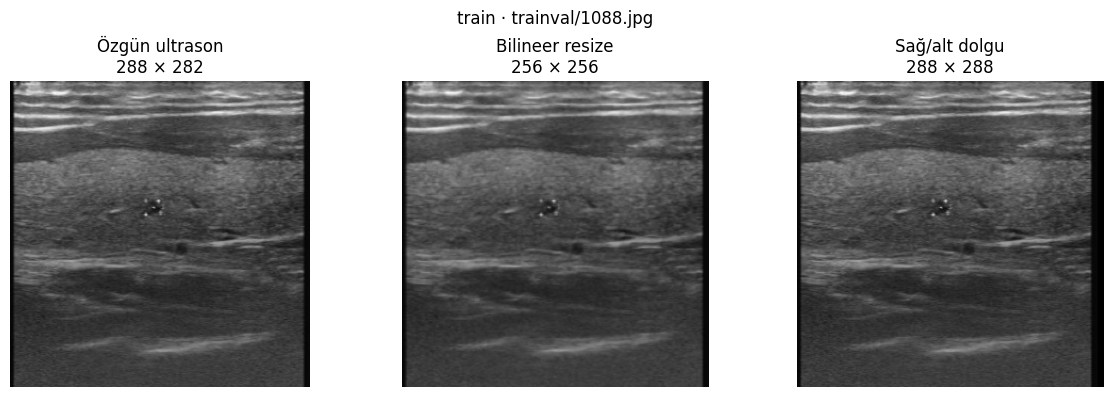

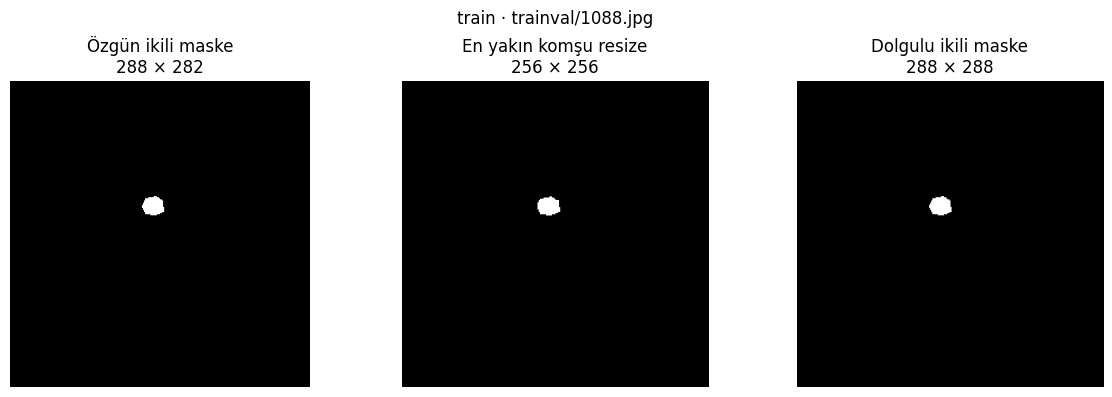

,İşlem,Izgara (Y × G),Izgara en/boy,Nodül pikseli,Geçerli piksel,Geçerli alanda nodül (%)
0,Özgün,288 × 282,0.9792,292,81216,0.3595
1,Resize,256 × 256,1.0000,237,65536,0.3616
2,Padding,288 × 288,1.0000,292,81216,0.3595


In [7]:
def preprocess_pair(image_path, mask_path, size=(256,256), threshold=128):
    with PILImage.open(image_path) as im, PILImage.open(mask_path) as ma:
        assert im.size == ma.size, f'Boyut uyumsuzluğu: {image_path.name}'
        x = np.asarray(im.convert('L').resize(size, resample=PILImage.Resampling.BILINEAR), dtype=np.float32)/255.0
        # JPEG artefaktlarını önce ikilileştir, sonra etiket maskesini NN ile yeniden boyutlandır.
        raw_mask = np.asarray(ma.convert('L'))
        binary_pil = PILImage.fromarray((raw_mask >= threshold).astype(np.uint8))
        y = np.asarray(binary_pil.resize(size, resample=PILImage.Resampling.NEAREST), dtype=np.uint8)
    return x[..., None], y[..., None]

small = trainval.loc[trainval["foreground_pixels"].gt(0)].sort_values(
    ["foreground_pixels", "filename"]
).iloc[0]
original, target = read_image_mask(small.image_path, small.mask_path, cfg)
resized_image, resized_mask = preprocess_pair(small.image_path, small.mask_path)
resized_image, resized_mask = resized_image[..., 0], resized_mask[..., 0]
padded, padded_target, valid_small, _ = preprocess_native_pair(small.image_path, small.mask_path, cfg)
small_id = f"{small['subset']} · {small['split']}/{small['filename']}"

show_panels([(original, "Özgün ultrason", 255), (resized_image, "Bilineer resize", 1),
             (padded, "Sağ/alt dolgu", 1)], small_id)
show_panels([(target, "Özgün ikili maske", 1), (resized_mask, "En yakın komşu resize", 1),
             (padded_target, "Dolgulu ikili maske", 1)], small_id)
display(pd.DataFrame([
    {"İşlem": name, "Izgara (Y × G)": hw(mask.shape),
     "Izgara en/boy": mask.shape[1] / mask.shape[0], "Nodül pikseli": int(mask.sum()),
     "Geçerli piksel": valid_count, "Geçerli alanda nodül (%)": 100 * mask.sum() / valid_count}
    for name, mask, valid_count in [
        ("Özgün", target, target.size), ("Resize", resized_mask, resized_mask.size),
        ("Padding", padded_target, int(valid_small.sum()))
    ]
]).round(4))

## Sıfır dolgu hangi kenarlara ekleniyor?

Üç gerçek ultrason örneğinde yalnız sağa, yalnız alta ve her iki kenara
eklenen dolguyu gösteriyorum. **Turuncu** alan sağa, **mavi** alan alta,
**mor** alan ise iki dolgunun kesiştiği köşeye eklenen pikselleri gösteriyor.
Yeşil kesikli çizgi özgün görüntü alanının sınırı.

Renkler yalnızca görselleştirme için eklendi. Ön işleme kodu bu bölgeleri
sıfırla dolduruyor. Her örnekte dolguyu kaldırıp görüntü ve referans maske
piksellerinin dolgu öncesi değerlerle birebir eşleştiğini kontrol ediyorum.

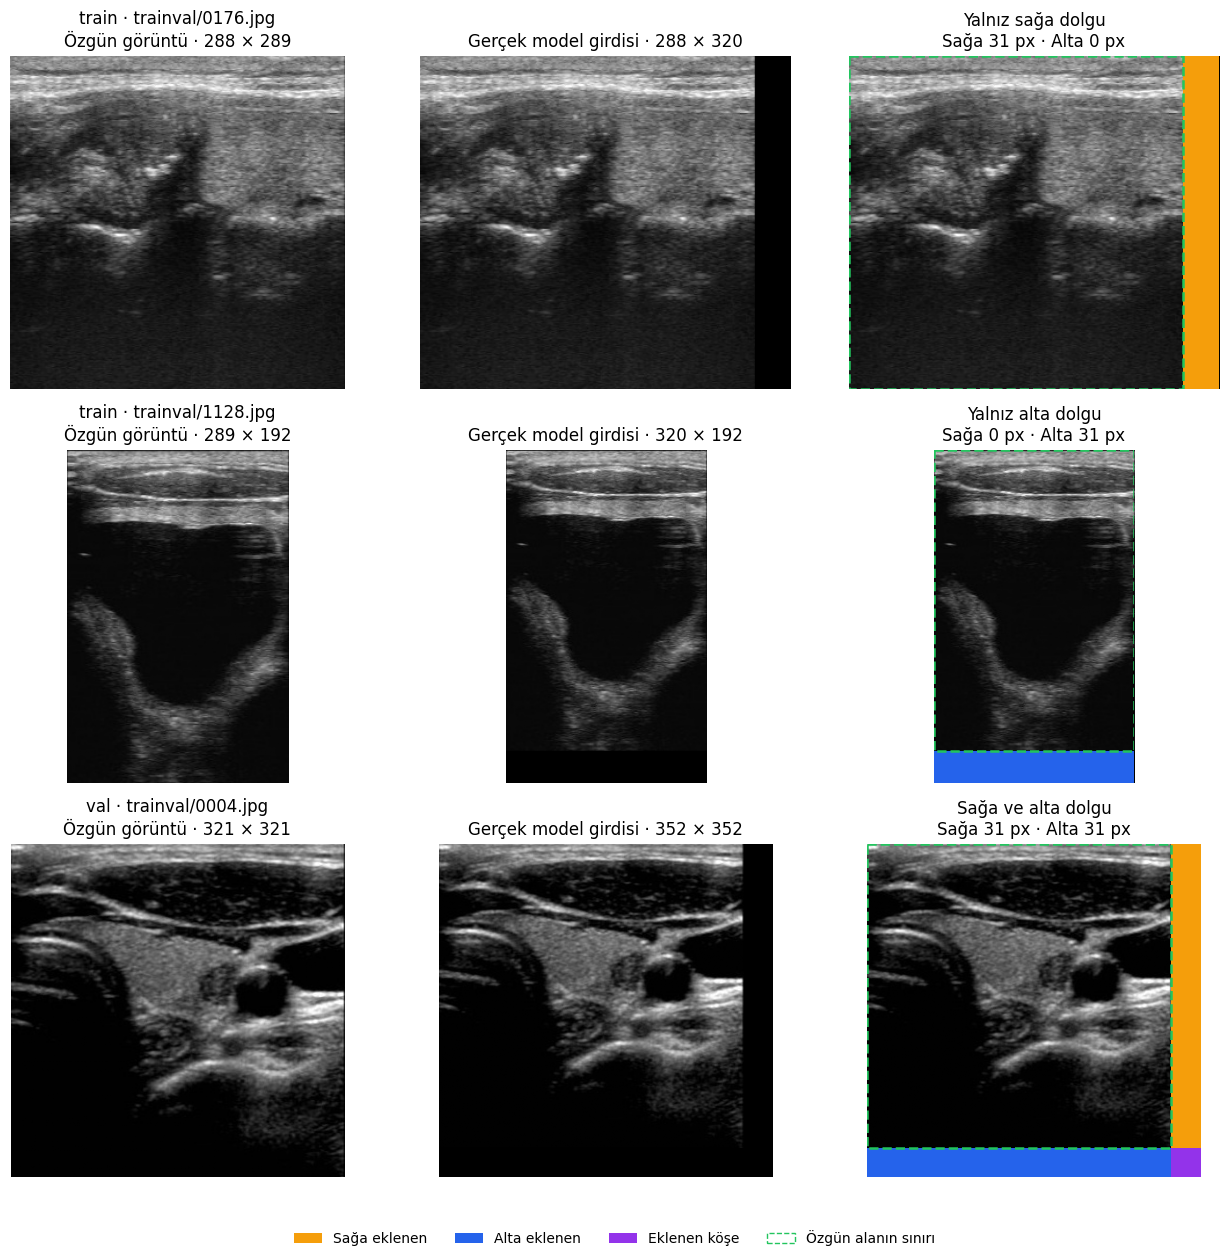

,Örnek,Özgün (Y × G),Dolgulu (Y × G),Sağa (px),Alta (px),Görüntü birebir,Maske birebir,Dolgu değerleri sıfır
0,train · trainval/0176.jpg,288 × 289,288 × 320,31,0,True,True,True
1,train · trainval/1128.jpg,289 × 192,320 × 192,0,31,True,True,True
2,val · trainval/0004.jpg,321 × 321,352 × 352,31,31,True,True,True


In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch, Rectangle

# Üç farklı dolgu durumunu gösterecek gerçek trainval örneklerini seç.
multiple = cfg.pad_multiple
candidates = pairs.loc[pairs["split"].eq("trainval")].copy()
candidates["alt"] = (-candidates["height"]) % multiple
candidates["sag"] = (-candidates["width"]) % multiple

groups = {
    "Yalnız sağa dolgu": (candidates["alt"] == 0) & (candidates["sag"] > 0),
    "Yalnız alta dolgu": (candidates["alt"] > 0) & (candidates["sag"] == 0),
    "Sağa ve alta dolgu": (candidates["alt"] > 0) & (candidates["sag"] > 0),
}

examples = []
for title, condition in groups.items():
    group = candidates.loc[condition].sort_values(
        ["alt", "sag", "filename"], ascending=[False, False, True]
    )
    if group.empty:
        print(f"Bu veri kopyasında örnek bulunamadı: {title}")
        continue
    examples.append((title, group.iloc[0]))

if not examples:
    raise ValueError("Dolgu gerektiren örnek bulunamadı.")

colors = {"sag": "#f59e0b", "alt": "#2563eb", "kose": "#9333ea"}
fig, axes = plt.subplots(
    len(examples), 3, figsize=(13, 4.2 * len(examples)), squeeze=False
)
checks = []

for panel, (title, row) in zip(axes, examples):
    image, mask = read_image_mask(row.image_path, row.mask_path, cfg)
    scaled = normalize_intensity(image, cfg)
    padded_image, padded_mask, valid, info = preprocess_native_pair(
        row.image_path, row.mask_path, cfg, augment=False
    )

    h, w = image.shape
    padded_h, padded_w = padded_image.shape
    bottom, right = padded_h - h, padded_w - w
    sample_id = f"{row['subset']} · {row['split']}/{row['filename']}"

    image_matches = np.array_equal(padded_image[:h, :w], scaled)
    mask_matches = np.array_equal(padded_mask[:h, :w], mask)
    padding_is_zero = (
        np.all(padded_image[valid == 0] == 0)
        and np.all(padded_mask[valid == 0] == 0)
    )

    panel[0].imshow(scaled, cmap="gray", vmin=0, vmax=1)
    panel[0].set_title(f"{sample_id}\nÖzgün görüntü · {h} × {w}")

    panel[1].imshow(padded_image, cmap="gray", vmin=0, vmax=1)
    panel[1].set_title(f"Gerçek model girdisi · {padded_h} × {padded_w}")

    panel[2].imshow(padded_image, cmap="gray", vmin=0, vmax=1)
    panel[2].set_title(f"{title}\nSağa {right} px · Alta {bottom} px")

    # imshow piksel merkezlerini tam sayıya yerleştirir.
    # Dikdörtgenleri yarım piksel kaydırarak kenarlara hizalıyoruz.
    regions = [
        (w, 0, right, h, colors["sag"]),
        (0, h, w, bottom, colors["alt"]),
        (w, h, right, bottom, colors["kose"]),
    ]
    for x, y, width, height, color in regions:
        if width and height:
            panel[2].add_patch(Rectangle(
                (x - 0.5, y - 0.5), width, height, facecolor=color
            ))

    panel[2].add_patch(Rectangle(
        (-0.5, -0.5), w, h, fill=False,
        edgecolor="#22c55e", linestyle="--", linewidth=1.8,
    ))

    for axis in panel:
        axis.axis("off")

    checks.append({
        "Örnek": sample_id,
        "Özgün (Y × G)": f"{h} × {w}",
        "Dolgulu (Y × G)": f"{padded_h} × {padded_w}",
        "Sağa (px)": right,
        "Alta (px)": bottom,
        "Görüntü birebir": image_matches,
        "Maske birebir": mask_matches,
        "Dolgu değerleri sıfır": padding_is_zero,
    })

fig.legend(
    handles=[
        Patch(facecolor=colors["sag"], label="Sağa eklenen"),
        Patch(facecolor=colors["alt"], label="Alta eklenen"),
        Patch(facecolor=colors["kose"], label="Eklenen köşe"),
        Patch(facecolor="none", edgecolor="#22c55e", linestyle="--",
              label="Özgün alanın sınırı"),
    ],
    loc="lower center", ncol=4, frameon=False,
)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()
plt.close(fig)

display(pd.DataFrame(checks))

### Görselin yorumu

Solda özgün piksel ızgarası, ortada modelin kullandığı sıfır dolgulu girdi,
sağda ise eklenen piksellerin renkle işaretlenmiş hâli yer alıyor. Bir boyut
zaten 32’nin katıysa o yönde dolgu eklenmiyor.

Tablodaki “Görüntü birebir” ve “Maske birebir” kontrolleri `True` olduğunda,
yeşil sınır içindeki görüntü ve maske piksellerinin dolgu öncesiyle eşleştiğini
görüyorum. Bu kontrol, dolgunun görüntünün özgün alanını kesmeden veya yeniden
örneklemeden boyut uyumu sağladığını gösteriyor.

Resize yeni bir piksel ızgarası oluşturur. Görüntüde bilineer yöntem komşu değerleri kullanır. İkili maskede en yakın komşu yöntemi 0 ve 1 etiketlerini korur, ancak örneklenen konumlar değişebilir. Ham piksel sayısını farklı ızgaralar arasında doğrudan nodül kaybı olarak yorumlamıyorum. Padding satırındaki en/boy, dolgu dahil tuvale aittir. Geçerli alanın geometrisi korunur.

Bu denetim kaynak piksel ızgarasının korunmasını ölçer. Dice etkisini ölçmek için aynı deney koşullarında iki ön işleme yöntemini ayrı ayrı eğitip değerlendirmek gerekir.

## Yöntem özeti

| İşlem | Gerekçe | Doğrulama çıktısı |
|---|---|---|
| Mevcut ayrımı ve dosyaları doğrulama | Modeller için ortak örnek üyeliğini korumak | 2. bölümde manifest, dosya ve içerik tablosu |
| Gri ton, eşikleme ve ölçekleme | Tek kanallı girdi ve ikili referans etiketi hazırlamak | 3–4. bölümlerde değer, tip ve aralık tabloları |
| Eğitimde ortak yatay çevirme | Yön çeşitliliği sağlarken görüntü–maske hizasını korumak | 4. bölümde kontrollü görsel ve eşitlik kontrolleri |
| Sağ/alt dolgu ve geçerli alan | Katman boyutlarını uyumlu tutup özgün piksel ızgarasını korumak | 5–6. bölümlerde boyut, tensör ve piksel denetimleri |

### Özet

EDA sonrasında Base U-Net ve U-Net 3+ için ortak görüntü ayrımını kullandım. Ultrasonu gri tonda okuyup 255’e böldüm, referans maskesini 128 eşiğiyle ikilileştirdim ve yatay çevirmeyi yalnız eğitimde görüntü ve maskeye birlikte uyguladım. Özgün piksel ızgarasını korumak için sağa ve alta sıfır ekleyerek boyutları 32 katına tamamladım. Geçerli alan maskesiyle dolguyu kayıp hesabının dışında tuttum. Bu notebook’un son tablosu, mevcut veri kopyasında kaç çiftin doğrulandığını ve dolgu geri alındığında kaç çiftin piksel düzeyinde eşleştiğini gösteriyor.

## 8 · Son doğrulama özeti

Bu çalıştırmada elde edilen ayrım sayılarını, örnek dönüşümlerini ve piksel denetimi sonucunu tek tabloda topluyorum.

In [8]:
report = [
    ("Eğitim / doğrulama / test", f"{counts['train']} / {counts['val']} / {counts['test']}"),
    ("Okunabilen çift", int(audit_table["Okunabilen çift"].sum())),
    ("Dosya ve içerik sorunu", len(file_issues)),
    ("Alt kümeler arası aynı görüntü hash’i", pairs.loc[cross_split, "image_hash"].nunique()),
    ("Örnek maske değerleri", np.unique(binary).tolist()),
    ("Eğitim örneği", f"{label} · {hw(raw.shape)} → {hw(px.shape)}"),
    ("test/0000.jpg · özgün → dolgulu → geri alınan", test_sizes),
    ("Trainval padding · kontrol / geçen / uyuşmayan",
     f"{padding_summary['Kontrol edilen']} / {padding_summary['Geçen']} / {padding_summary['Uyuşmayan']}"),
    ("İlk padding uyuşmazlıkları", [item[0] for item in padding_issues[:5]] or "Yok"),
]
display(pd.DataFrame(report, columns=["Kontrol", "Bu çalıştırmanın sonucu"]))
if padding_issues:
    raise AssertionError("Padding denetiminde uyuşmazlık var. 6. bölümdeki örnek kimliklerini incele.")

,Kontrol,Bu çalıştırmanın sonucu
0,Eğitim / doğrulama / test,2303 / 576 / 614
1,Okunabilen çift,3493
2,Dosya ve içerik sorunu,0
3,Alt kümeler arası aynı görüntü hash’i,0
4,Örnek maske değerleri,"[0, 1]"
5,Eğitim örneği,train · trainval/0000.jpg · 402 × 314 → 416 × 320
6,test/0000.jpg · özgün → dolgulu → geri alınan,332 × 365 → 352 × 384 → 332 × 365
7,Trainval padding · kontrol / geçen / uyuşmayan,2879 / 2879 / 0
8,İlk padding uyuşmazlıkları,Yok


## Sonuç

Bu çalıştırmada 3.493 ultrason–maske çiftinin tamamını okuyabildim ve
doğrulanmış manifestle karşılaştırdığımda dosya veya içerik uyuşmazlığı
bulmadım. Eğitim, doğrulama ve test grupları sırasıyla 2.303, 576 ve
614 örnek olarak korundu.

Görüntüleri sabit bir kareye yeniden örneklemek yerine sağa ve alta
sıfır dolgu ekleyerek boyutları 32’nin katına tamamladım. Geçerli alan
maskesiyle bu ek pikselleri kayıp hesabının dışında tuttum. Dolguyu geri
aldığımda 2.879 eğitim ve doğrulama çiftinin tamamında, dolgu öncesi
ölçeklenmiş görüntü ile ikili referans maskenin piksel düzeyinde eşleştiğini
doğruladım. Resize örneği farklı bir piksel ızgarası oluştururken padding
özgün alanı korudu. Bu inceleme, ön işlemenin piksel koruma özelliğini
doğruladı. Segmentasyon skoruna etkisini ölçmek ayrı bir deney gerektirir.